In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path(".")

In [41]:
!pip install plotstyle

In [42]:
import plotstyle as ps
ps.use

<function plotstyle.core.style.use(style: 'str | list[str]', *, latex: 'bool | str' = False, seaborn_compatible: 'bool' = False) -> 'JournalStyle'>

In [43]:
df = pd.read_csv("goodman_fatigue.csv")
X = df[["sigma_m_MPa", "sigma_a_MPa"]].to_numpy() / 100.0   # units of 100 MPa
t = df["failed"].to_numpy()                                 # targets 0 / 1


In [44]:
df.head(10)

,sigma_m_MPa,sigma_a_MPa,failed
0,464.4,143.3,1
1,263.3,228.4,1
2,515.2,271.0,1
3,418.4,216.2,1
4,56.5,289.0,1
5,585.4,234.6,1
6,456.7,260.0,1
7,471.6,34.2,0
8,556.1,196.2,1
9,386.3,290.9,1


In [45]:
w, b, eta = np.zeros(2), 0.0, 1.0

In [46]:
history, snapshots = [], {}                    # errors per epoch, w after k updates
for epoch in range(1000):
    errors = 0
    for xi, ti in zip(X, t):
        y = float(w @ xi + b > 0)              # step activation
        if y != ti:                            # update only when wrong
            w += eta * (ti - y) * xi
            b += eta * (ti - y)
            errors += 1
            k = sum(history) + errors          # total number of updates so far
            if k in (3, 10, 30):
                snapshots[k] = (w.copy(), b)
    history.append(errors)
    if errors == 0:
        break

In [47]:
print(f"converged after {epoch + 1} epochs, {sum(history)} weight updates")
print(f"w = {w},  b = {b:.2f}")
# decision line  w1*sm + w2*sa + b = 0  ->  intercepts are the material limits
print(f"learned  S_ut = {-b / w[0] * 100:6.1f} MPa   (true 600)")
print(f"learned  S_e  = {-b / w[1] * 100:6.1f} MPa   (true 250)")

converged after 3 epochs, 75 weight updates
w = [2.7   6.956],  b = -17.00
learned  S_ut =  629.6 MPa   (true 600)
learned  S_e  =  244.4 MPa   (true 250)


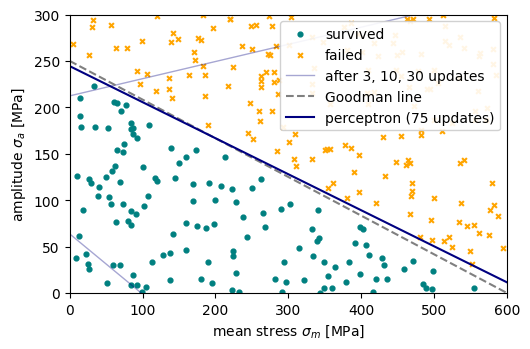

In [49]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
sm = np.linspace(0, 600, 2)
line = lambda w, b: -(w[0] * sm / 100 + b) / w[1] * 100
ax.scatter(*(X[t == 0].T * 100), s=12, c='teal', label="survived")
ax.scatter(*(X[t == 1].T * 100), s=12, c='orange', marker="x", label="failed")
for k, (wk, bk) in snapshots.items():
    ax.plot(sm, line(wk, bk), c='navy', lw=1, alpha=0.35,
            label="after 3, 10, 30 updates" if k == 3 else None)
ax.plot(sm, 250 * (1 - sm / 600), "--", c='grey', label="Goodman line")
ax.plot(sm, line(w, b), c='navy', label=f"perceptron ({sum(history)} updates)")
ax.set(xlabel=r"mean stress $\sigma_m$ [MPa]", ylabel=r"amplitude $\sigma_a$ [MPa]",
       xlim=(0, 600), ylim=(0, 300))
ax.legend(loc="upper right", frameon=True, framealpha=0.9)
fig.tight_layout()
fig.savefig("perceptron_goodman.pdf")